# Actividad 1 – Regresión lineal: predicción del consumo de combustible (MPG)
**Materia:** Aprendizaje Automático 

**Objetivo:** encontrar un dataset con una variable objetivo continua y aplicar regresión lineal para predecirla a partir de las demás variables.

Sigo el flujo de trabajo: pregunta → datos → explorar y preparar → modelar y analizar → comunicar. Dentro del método pedido en la consigna:
1. Preparación y organización de datos
2. Exploración de los datos
3. Modelado de datos

## 0. La pregunta
> *¿Se puede predecir el consumo de combustible de un auto (`mpg`, millas por galón) a partir de sus características técnicas (cilindros, cilindrada, potencia, peso, aceleración, año y origen)? ¿Con qué error?*

- **Variable objetivo `y`:** `mpg` → es continua, por lo tanto es un problema de **regresión** (la tarea la define el significado de `y`).
- **Entradas `X`:** características del auto disponibles antes de medir el consumo. No hay variables que "filtren" el resultado (no incluyo nada derivado de `mpg`).
- **Métrica de éxito:** error absoluto medio (en mpg) y R² sobre datos de prueba.

**Dataset:** *Auto MPG*, copia del repositorio `seaborn-data`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn import linear_model
import sklearn.metrics as sm

## 1. Preparación y organización de datos

### 1.1 Obtener los datos (pandas)

In [2]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"
try:
    df = pd.read_csv(url)
except Exception:
    df = pd.read_csv("mpg.csv")   # copia local si no hay internet
print(df.shape)
df.head()

(398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


### 1.2 Inspeccionar antes de transformar
Reviso tipos, rangos, faltantes, duplicados y categorías, y busco cosas imposibles o poco probables.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 28.1 KB


In [4]:
print("Faltantes por columna:"); print(df.isna().sum())
print("\nFilas duplicadas:", df.duplicated().sum())
print("\nCategorías de origin:"); print(df["origin"].value_counts())
print("\nNombres de auto únicos:", df["name"].nunique(), "de", len(df))

Faltantes por columna:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64

Filas duplicadas: 0

Categorías de origin:
origin
usa       249
japan      79
europe     70
Name: count, dtype: int64

Nombres de auto únicos: 305 de 398


In [5]:
# Reglas de calidad conocidas (se pueden chequear antes de separar los datos)
print("mpg <= 0:", (df["mpg"] <= 0).sum())
print("peso <= 0:", (df["weight"] <= 0).sum())
print("horsepower <= 0:", (df["horsepower"] <= 0).sum())
print("Rango de model_year:", df["model_year"].min(), "-", df["model_year"].max())
df.describe().round(2)

mpg <= 0: 0
peso <= 0: 0
horsepower <= 0: 0
Rango de model_year: 70 - 82


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.00,398.00,398.00,392.00,398.00,398.00,398.00
mean,23.51,5.45,193.43,104.47,2970.42,15.57,76.01
std,7.82,1.70,104.27,38.49,846.84,2.76,3.70
min,9.00,3.00,68.00,46.00,1613.00,8.00,70.00
25%,17.50,4.00,104.25,75.00,2223.75,13.82,73.00
50%,23.00,4.00,148.50,93.50,2803.50,15.50,76.00
75%,29.00,8.00,262.00,126.00,3608.00,17.18,79.00
max,46.60,8.00,455.00,230.00,5140.00,24.80,82.00


**Decisiones:**
- `name` casi no se repite, es un **identificador**, no una medida: lo excluyo de las entradas.
- `origin` es **categórica nominal** (sin jerarquía entre países): la voy a codificar con *one-hot*, no con 0/1/2, para no inventar un orden.
- `horsepower` tiene faltantes: en lugar de borrar filas los **imputo con la mediana**, pero lo hago **dentro de un pipeline ajustado solo con el entrenamiento**. Imputar antes de separar los datos sería fuga de información.
- Antes de decidir nada aprendido de la distribución, primero separo entrenamiento y prueba.

### 1.3 Separar X e y, y reservar datos de prueba

In [6]:
df = df.drop(columns="name")           # identificador
y = df["mpg"]
X = df.drop(columns="mpg")

X_entrenamiento, X_prueba, Y_entrenamiento, Y_prueba = train_test_split(
    X, y, test_size=0.2, random_state=42)
print("Entrenamiento:", X_entrenamiento.shape, "| Prueba:", X_prueba.shape)
print("Faltantes en entrenamiento:", X_entrenamiento.isna().sum().sum(),
      "| en prueba:", X_prueba.isna().sum().sum())

Entrenamiento: (318, 7) | Prueba: (80, 7)
Faltantes en entrenamiento: 5 | en prueba: 1


Uso `train_test_split` con mezcla aleatoria en lugar del corte secuencial porque este dataset viene ordenado por año de modelo: un corte secuencial dejaría en prueba solo los autos más nuevos. `random_state=42` hace que la partición sea reproducible.

## 2. Exploración de los datos (AED)
Exploro **solo con el conjunto de entrenamiento**, así las decisiones que tome no dependen de la prueba. Uso los gráficos con título y ejes rotulados.

In [7]:
entrenamiento = X_entrenamiento.copy()
entrenamiento["mpg"] = Y_entrenamiento
entrenamiento.describe().round(2)

,cylinders,displacement,horsepower,weight,acceleration,model_year,mpg
count,318.00,318.00,313.00,318.00,318.00,318.0,318.00
mean,5.43,191.90,103.28,2969.02,15.64,76.1,23.61
std,1.68,102.98,37.36,840.62,2.76,3.6,7.93
min,3.00,68.00,46.00,1613.00,8.00,70.0,9.00
25%,4.00,98.50,75.00,2220.00,13.90,73.0,17.50
50%,4.00,148.50,92.00,2822.50,15.50,76.0,22.45
75%,6.00,259.50,122.00,3597.25,17.30,79.0,29.72
max,8.00,455.00,225.00,5140.00,24.80,82.0,46.60


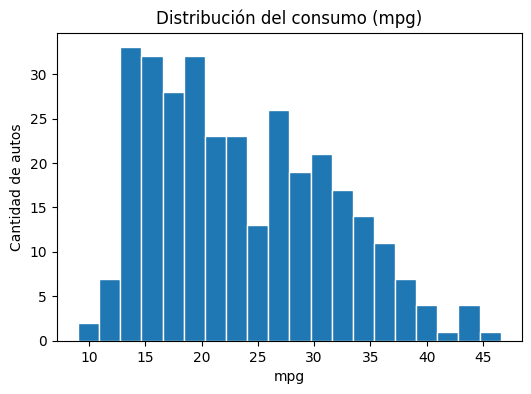

In [8]:
plt.figure(figsize=(6, 4))
plt.hist(entrenamiento["mpg"], bins=20, color="C0", edgecolor="white")
plt.xlabel("mpg"); plt.ylabel("Cantidad de autos"); plt.title("Distribución del consumo (mpg)")
plt.show()

El histograma muestra una distribución con cola hacia la derecha (pocos autos muy eficientes), sin valores imposibles.

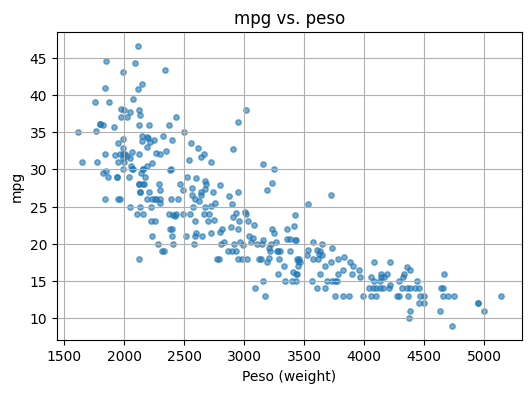

In [9]:
plt.figure(figsize=(6, 4))
plt.scatter(entrenamiento["weight"], entrenamiento["mpg"], s=15, alpha=0.6)
plt.xlabel("Peso (weight)"); plt.ylabel("mpg"); plt.title("mpg vs. peso")
plt.grid(True); plt.show()

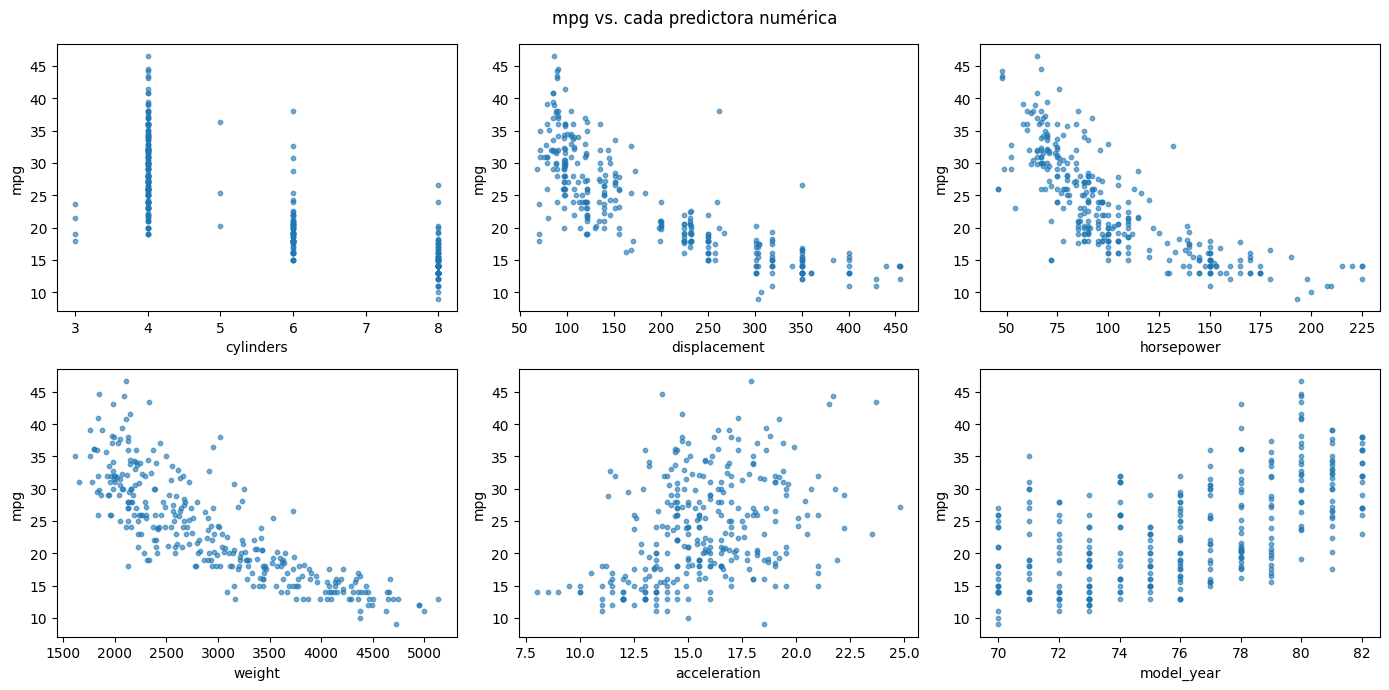

In [10]:
columnas_num = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
fig, ejes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(ejes.ravel(), columnas_num):
    ax.scatter(entrenamiento[col], entrenamiento["mpg"], s=10, alpha=0.6)
    ax.set_xlabel(col); ax.set_ylabel("mpg")
fig.suptitle("mpg vs. cada predictora numérica"); plt.tight_layout(); plt.show()

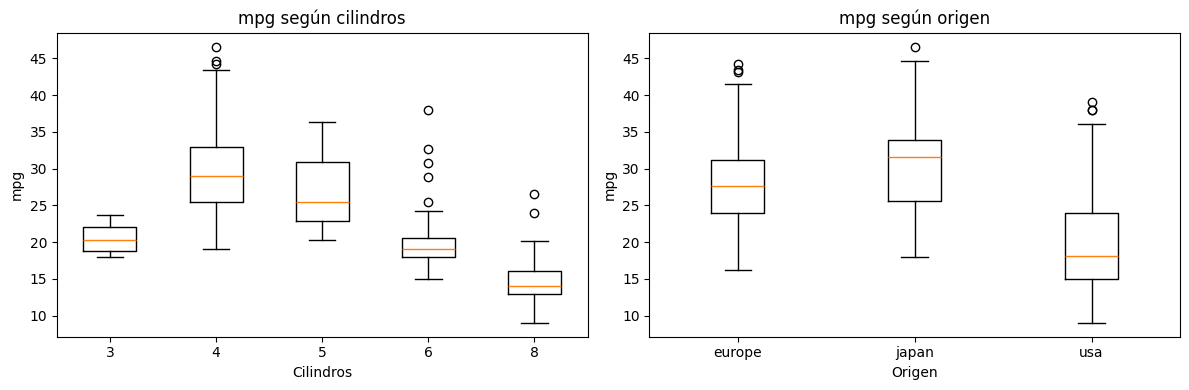

In [11]:
# Valores atípicos: boxplot de mpg según cilindros y según origen
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
niveles_cil = sorted(entrenamiento["cylinders"].unique())
ejes[0].boxplot([entrenamiento.loc[entrenamiento["cylinders"] == c, "mpg"] for c in niveles_cil],
                tick_labels=[str(c) for c in niveles_cil])
ejes[0].set_xlabel("Cilindros"); ejes[0].set_ylabel("mpg"); ejes[0].set_title("mpg según cilindros")

niveles_ori = sorted(entrenamiento["origin"].unique())
ejes[1].boxplot([entrenamiento.loc[entrenamiento["origin"] == o, "mpg"] for o in niveles_ori],
                tick_labels=niveles_ori)
ejes[1].set_xlabel("Origen"); ejes[1].set_ylabel("mpg"); ejes[1].set_title("mpg según origen")
plt.tight_layout(); plt.show()

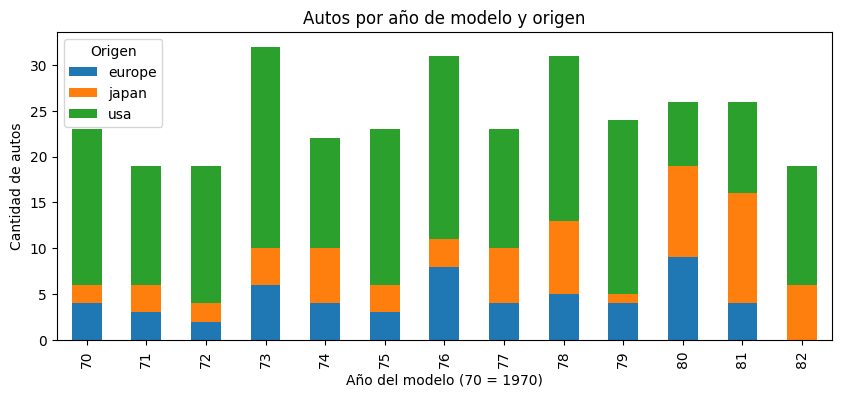

In [12]:
# Distribución de autos por año de modelo y origen
tabla = pd.crosstab(entrenamiento["model_year"], entrenamiento["origin"])
tabla.plot(kind="bar", stacked=True, figsize=(10, 4))
plt.xlabel("Año del modelo (70 = 1970)"); plt.ylabel("Cantidad de autos")
plt.title("Autos por año de modelo y origen"); plt.legend(title="Origen"); plt.show()

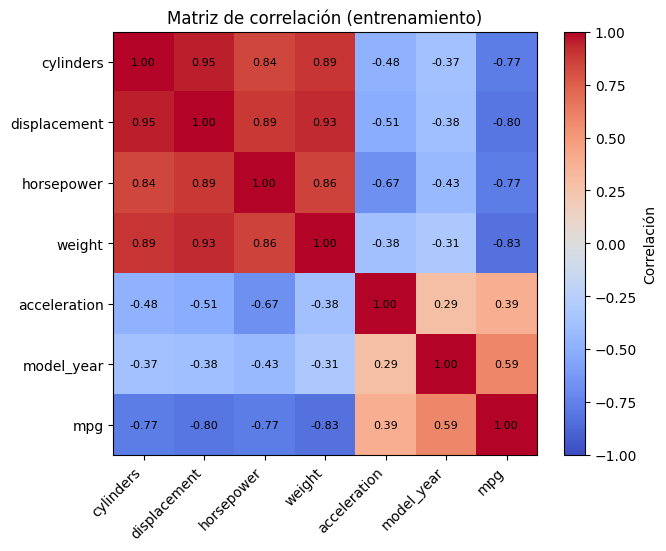

weight         -0.83
displacement   -0.80
horsepower     -0.77
cylinders      -0.77
acceleration    0.39
model_year      0.59
Name: mpg, dtype: float64

Correlaciones entre predictoras:
              weight  displacement  horsepower  cylinders
weight          1.00          0.93        0.86       0.89
displacement    0.93          1.00        0.89       0.95
horsepower      0.86          0.89        1.00       0.84
cylinders       0.89          0.95        0.84       1.00


In [13]:
corr = entrenamiento.drop(columns="origin").corr()
plt.figure(figsize=(7, 5.5))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlación")
plt.xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.title("Matriz de correlación (entrenamiento)"); plt.show()
print(corr["mpg"].drop("mpg").sort_values().round(2))
print("\nCorrelaciones entre predictoras:")
print(corr.loc[["weight", "displacement", "horsepower", "cylinders"],
               ["weight", "displacement", "horsepower", "cylinders"]].round(2))

**Qué encuentro en la exploración (verificable en las salidas de arriba):**
- Peso, cilindrada, potencia y cilindros están fuertemente correlacionados de forma **negativa** con `mpg`.
- Esas mismas predictoras están muy correlacionadas **entre sí** (multicolinealidad): los coeficientes individuales serán poco estables y tiene sentido probar Ridge.
- La relación de `mpg` con peso y potencia parece **curva**, lo que limita a un modelo lineal.
- El origen y el año de modelo también se asocian con `mpg` (los autos más nuevos tienden a consumir menos).
- Hay más autos de un origen (usa) que de los otros: hay que tenerlo presente al interpretar.

## 3. Modelado de datos
### 3.1 Preprocesamiento reproducible con `ColumnTransformer` y `Pipeline`
Cada grupo de columnas recibe el tratamiento que corresponde a su tipo:

| Columnas | Tipo | Tratamiento |
|---|---|---|
| `cylinders`, `displacement`, `horsepower`, `weight`, `acceleration`, `model_year` | numéricas | `SimpleImputer(median)` + `StandardScaler` |
| `origin` | categórica nominal | `SimpleImputer(most_frequent)` + `OneHotEncoder` |

- La mediana es menos sensible a extremos que la media.
- Estandarizo aunque la regresión lineal simple no lo necesite: Ridge sí es sensible a la escala, y así los coeficientes quedan comparables.
- En `OneHotEncoder` uso `drop="first"`: como el modelo lineal tiene intercepto, conservar todas las columnas dummy generaría redundancia exacta. `handle_unknown="ignore"` evita un error si aparece un origen nuevo.
- Todo se **ajusta (`fit`) solo con el entrenamiento** y se reutiliza (`transform`) en la prueba.

In [14]:
columnas_num = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
columnas_cat = ["origin"]

preprocesador = ColumnTransformer([
    ("num", Pipeline([("imputar", SimpleImputer(strategy="median")),
                      ("escalar", StandardScaler())]), columnas_num),
    ("cat", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore",
                                                sparse_output=False))]), columnas_cat),
])

# Revisar la matriz resultante antes de entrenar
preprocesador.fit(X_entrenamiento)
X_ent_prep = preprocesador.transform(X_entrenamiento)
print("Forma de la matriz de entrada:", X_ent_prep.shape)
print("Columnas:", list(preprocesador.get_feature_names_out()))
print("\nMediana de horsepower aprendida del ENTRENAMIENTO:",
      preprocesador.named_transformers_["num"]["imputar"].statistics_[2])
print("Faltantes tras preprocesar:", np.isnan(X_ent_prep).sum())

Forma de la matriz de entrada: (318, 8)
Columnas: ['num__cylinders', 'num__displacement', 'num__horsepower', 'num__weight', 'num__acceleration', 'num__model_year', 'cat__origin_japan', 'cat__origin_usa']

Mediana de horsepower aprendida del ENTRENAMIENTO: 92.0
Faltantes tras preprocesar: 0


### 3.2 Regresión lineal (mínimos cuadrados)

In [15]:
modelo_lineal = Pipeline([("prep", preprocesador),
                          ("modelo", linear_model.LinearRegression())])
modelo_lineal.fit(X_entrenamiento, Y_entrenamiento)
Y_predicha_de_prueba = modelo_lineal.predict(X_prueba)

nombres = modelo_lineal[:-1].get_feature_names_out()
coef = pd.Series(modelo_lineal[-1].coef_, index=nombres).sort_values()
print("Intersección (beta):", round(modelo_lineal[-1].intercept_, 3))
print(coef.round(3))

Intersección (beta): 25.482
num__weight         -5.912
cat__origin_usa     -2.948
num__horsepower     -0.545
num__cylinders      -0.279
cat__origin_japan   -0.274
num__acceleration    0.186
num__displacement    2.036
num__model_year      2.971
dtype: float64


In [16]:
def evaluar(y_real, y_pred):
    return {
        "Error absoluto medio": round(sm.mean_absolute_error(y_real, y_pred), 2),
        "Error cuadrático medio": round(sm.mean_squared_error(y_real, y_pred), 2),
        "Error absoluto mediano": round(sm.median_absolute_error(y_real, y_pred), 2),
        "Varianza explicada": round(sm.explained_variance_score(y_real, y_pred), 2),
        "R2": round(sm.r2_score(y_real, y_pred), 2),
    }
res_lineal = evaluar(Y_prueba, Y_predicha_de_prueba)
for k, v in res_lineal.items(): print(f"{k} = {v}")

Error absoluto medio = 2.29
Error cuadrático medio = 8.34
Error absoluto mediano = 1.87
Varianza explicada = 0.85
R2 = 0.84


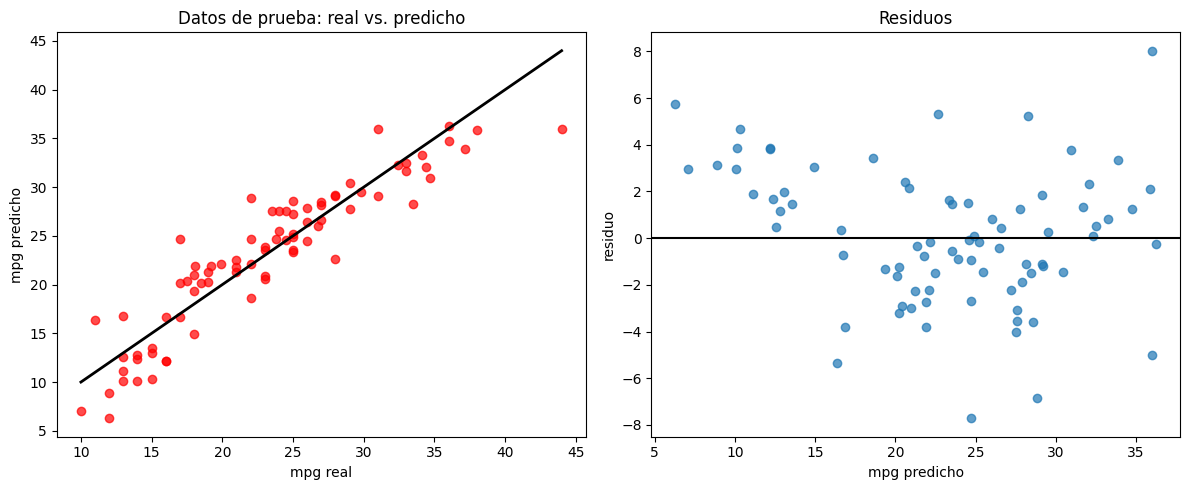

In [17]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 5))
ejes[0].scatter(Y_prueba, Y_predicha_de_prueba, color="red", alpha=0.7)
lim = [Y_prueba.min(), Y_prueba.max()]
ejes[0].plot(lim, lim, color="black", linewidth=2)
ejes[0].set_xlabel("mpg real"); ejes[0].set_ylabel("mpg predicho"); ejes[0].set_title("Datos de prueba: real vs. predicho")

residuos = Y_prueba - Y_predicha_de_prueba
ejes[1].scatter(Y_predicha_de_prueba, residuos, alpha=0.7)
ejes[1].axhline(0, color="black")
ejes[1].set_xlabel("mpg predicho"); ejes[1].set_ylabel("residuo"); ejes[1].set_title("Residuos")
plt.tight_layout(); plt.show()

### 3.3 Regresión contraída (Ridge)
Agrega a la suma residual de cuadrados el término de penalización λ·Σβ². Elijo λ (`alpha`) por validación cruzada con `RidgeCV`, dentro del pipeline (solo con datos de entrenamiento).

In [18]:
modelo_ridge = Pipeline([("prep", preprocesador),
                         ("modelo", linear_model.RidgeCV(alphas=np.logspace(-3, 3, 50), cv=5))])
modelo_ridge.fit(X_entrenamiento, Y_entrenamiento)
Y_predicha_ridge = modelo_ridge.predict(X_prueba)
print("alpha elegido:", round(modelo_ridge[-1].alpha_, 3))
res_ridge = evaluar(Y_prueba, Y_predicha_ridge)
for k, v in res_ridge.items(): print(f"{k} = {v}")

alpha elegido: 2.024
Error absoluto medio = 2.28
Error cuadrático medio = 8.33
Error absoluto mediano = 1.74
Varianza explicada = 0.85
R2 = 0.85


### 3.4 Extensión: transformar la variable objetivo
Como la relación parece curva, pruebo predecir `log(mpg)`. Uso `TransformedTargetRegressor`, que aplica la transformación inversa automáticamente al predecir, de modo que las métricas quedan en mpg. (En clase vemos que transformar `y` requiere tratamiento separado con transformación inversa; por eso lo trato como extensión.)

In [19]:
modelo_log = TransformedTargetRegressor(
    regressor=Pipeline([("prep", preprocesador), ("modelo", linear_model.LinearRegression())]),
    func=np.log, inverse_func=np.exp)
modelo_log.fit(X_entrenamiento, Y_entrenamiento)
res_log = evaluar(Y_prueba, modelo_log.predict(X_prueba))
comparacion = pd.DataFrame({"Lineal": res_lineal, "Ridge": res_ridge, "Lineal con log(mpg)": res_log})
comparacion

,Lineal,Ridge,Lineal con log(mpg)
Error absoluto medio,2.29,2.28,1.77
Error cuadrático medio,8.34,8.33,5.66
Error absoluto mediano,1.87,1.74,1.43
Varianza explicada,0.85,0.85,0.90
R2,0.84,0.85,0.89


### 3.5 Robustez: validación cruzada sobre el entrenamiento
Con solo 79 datos de prueba, las métricas dependen mucho de la partición. Repito la evaluación con validación cruzada de 5 particiones **sobre el entrenamiento**. Como el preprocesamiento está dentro del pipeline, se reajusta en cada partición y no hay fuga de información.

In [20]:
modelos = {"Lineal": modelo_lineal, "Ridge": modelo_ridge, "Lineal con log(mpg)": modelo_log}
filas = {}
for nombre, m in modelos.items():
    r2 = cross_val_score(m, X_entrenamiento, Y_entrenamiento, cv=5, scoring="r2")
    filas[nombre] = {"R2 medio (CV)": round(r2.mean(), 3), "Desvío entre particiones": round(r2.std(), 3)}
pd.DataFrame(filas).T

,R2 medio (CV),Desvío entre particiones
Lineal,0.805,0.020
Ridge,0.805,0.020
Lineal con log(mpg),0.845,0.023


In [21]:
r2_train = sm.r2_score(Y_entrenamiento, modelo_lineal.predict(X_entrenamiento))
r2_test = sm.r2_score(Y_prueba, Y_predicha_de_prueba)
print(f"Regresión lineal: R2 entrenamiento = {r2_train:.2f} | R2 prueba = {r2_test:.2f}")

Regresión lineal: R2 entrenamiento = 0.82 | R2 prueba = 0.84


## 4. Conclusiones 
- **Pregunta:** sí, con estas variables se puede predecir el consumo con un error razonable: con regresión lineal el error absoluto medio en prueba es de 2.29 mpg y el R² de 0.84.
- **Preparación:** en lugar de borrar las filas con `horsepower` faltante, las imputé con la mediana del entrenamiento (92.0) dentro de un `Pipeline`. Así se conservaron los 398 registros y la prueba no participó de ninguna decisión de preparación. `origin` se codificó con one-hot (sin imponer orden entre países) y `name` se excluyó por ser un identificador.
- **Exploración:** peso, cilindrada, potencia y cilindros tienen correlación fuerte y negativa con `mpg` (entre -0.77 y -0.83), pero también están muy correlacionadas entre sí (0.84 a 0.95). La relación con `mpg` es algo curva.
- **Ridge vs. lineal:** rendimiento prácticamente idéntico (R² de 0.85 y 0.84 en prueba; ambos 0.805 en validación cruzada). Con pocas variables y 318 datos de entrenamiento la penalización no aporta una mejora apreciable.
- **Extensión con log(mpg):** mejora el R² en prueba a 0.89 y el R² de validación cruzada a 0.845, coherente con la curvatura observada.
- **Sobre la partición:** en una versión anterior de esta actividad (borrando las filas con faltantes y con otra partición aleatoria de 79 datos de prueba) el R² de la regresión lineal en prueba fue 0.79, y ahora es 0.84. La diferencia muestra que con un conjunto de prueba chico las métricas dependen de qué autos caen en él. Por eso me quedo más con el R² de validación cruzada (≈ 0.81 para el modelo lineal), que es una estimación más estable. También el R² de prueba (0.84) es algo mayor que el de entrenamiento (0.82), algo que suele pasar por azar de la partición y no indica un mejor modelo.
- **Interpretación de coeficientes:** con predictoras tan correlacionadas entre sí, no conviene leer cada coeficiente por separado. Por ejemplo, `displacement` sale con signo positivo pese a que su correlación con `mpg` es negativa: es un efecto típico de la multicolinealidad.
- **Limitaciones:** los datos son de autos de 1970 a 1982, por lo que no se debe extrapolar a autos actuales; `origin` está desbalanceado (249 usa, 79 japan, 70 europe); y el modelo lineal no captura del todo la curvatura de la relación.
